# Birthday Attack – Full Step-by-Step Technical Demonstration

This notebook keeps the supplied Birthday Attack logic and menu structure. The demonstration is made verbose so that each calculation is displayed before the corresponding result: Birthday Bound, random message, SHA-256 digest, truncation, stored hashes, comparison, collision, attempts, time, and the final interpretation.

## Case Study Rubric Mapping

- **Cryptographic Background:** SHA-256 and truncated hash output are stated in the program.
- **Vulnerability Identification:** reduced hash space and collision probability are identified.
- **Attack Methodology:** random-message collision search is printed step-by-step.
- **Real-World Impact:** the demonstration explains why insufficient hash size increases collision risk.
- **Countermeasures:** use an adequately large cryptographic hash output and avoid deliberate truncation in real systems.
- **Technical Demonstration:** the program performs the collision search, measures attempts/time, and plots the attack progress.
- **Lesson Learned:** the final output summarizes the security principle demonstrated.

The rubric does not require unrelated plots; the included plot directly visualizes the implemented attack.

     BIRTHDAY ATTACK - CRYPTOGRAPHIC HASH DEMO
Underlying hash function: SHA-256
The digest is intentionally truncated for demonstration.

MAIN MENU
------------------------------------------------------------
1. Random Input - Automatically search for collision
2. User Input   - Check collision between two messages
3. Change Hash Size
4. Exit
------------------------------------------------------------


Enter your choice:  1



Select demonstration hash size:
1. 8 bits  - Very fast
2. 12 bits - Fast
3. 16 bits - Recommended for demonstration
4. 20 bits - Larger search
5. 24 bits - Larger search


Enter your choice:  1



ATTACK MODEL
Goal: Find two different messages with the same truncated hash.
Hash function: SHA-256
Attack type: Birthday collision search
Demonstration model: Reduced/truncated hash space

ATTACK METHODOLOGY
1. Generate random messages.
2. Compute truncated SHA-256 for each message.
3. Store previously observed hashes.
4. Compare each new hash with stored hashes.
5. Stop when two different messages produce the same hash.

VULNERABILITY / WEAKNESS BEING DEMONSTRATED
A reduced hash space makes collisions much easier to observe.
This demonstrates the birthday-paradox principle.

RANDOM INPUT MODE
Generating random messages and searching for a collision...
Hash size: 8 bits
Theoretical 50% birthday bound: 18.84 attempts
------------------------------------------------------------

STEP-BY-STEP CALCULATION OF THE BIRTHDAY ATTACK
Step 1: Calculate the theoretical 50% Birthday Bound
Formula = sqrt(2 × 2^bits × ln(2))
        = sqrt(2 × 2^8 × ln(2))
        = sqrt(2 × 256 × 0.693147)
       

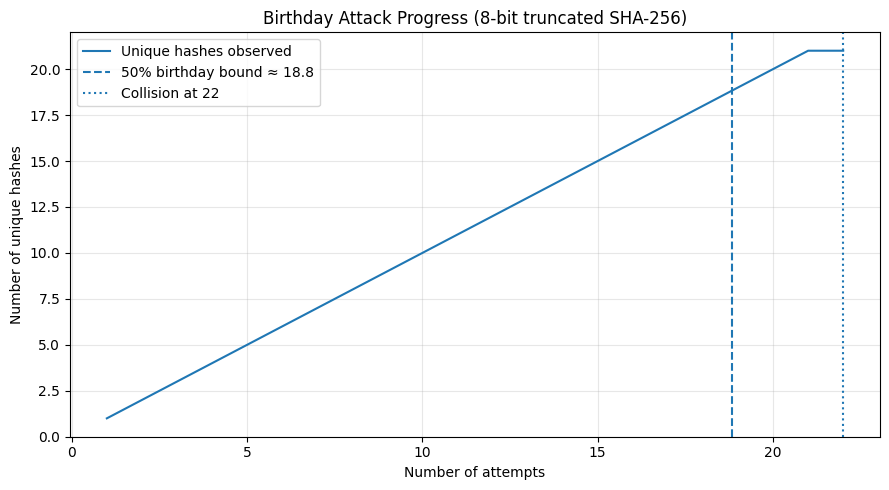


IMPACT
The demonstration shows that a smaller effective hash space
allows collisions to be found with far fewer attempts.
This illustrates why collision-resistant cryptographic hashes
require a sufficiently large output space.

COUNTERMEASURE
Use a cryptographically strong hash with an adequately large
output size and avoid deliberately truncated hashes in real systems.

LESSON LEARNED
Birthday attacks exploit the probability of collisions in a
finite hash space; reducing the hash size makes the attack easier.

Note: This is a controlled educational demonstration.
It does NOT demonstrate a collision in full SHA-256.

MAIN MENU
------------------------------------------------------------
1. Random Input - Automatically search for collision
2. User Input   - Check collision between two messages
3. Change Hash Size
4. Exit
------------------------------------------------------------


In [ ]:
import hashlib
import math
import random
import string
import time
import matplotlib.pyplot as plt

HASH_BITS = 16
MAX_ATTEMPTS = 1_000_000

def birthday_bound(bits):
    return math.sqrt(2 * (2 ** bits) * math.log(2))

def truncated_hash(message, bits):
    digest = hashlib.sha256(message.encode("utf-8")).digest()
    value = int.from_bytes(digest, "big")
    return value >> (256 - bits)

def random_message(length=12):
    characters = string.ascii_letters + string.digits
    return "".join(random.choice(characters) for _ in range(length))

def show_hash(message, bits):
    value = truncated_hash(message, bits)
    width = (bits + 3) // 4
    return f"{value:0{width}x}"

def random_attack(bits):
    print("\nSTEP-BY-STEP CALCULATION OF THE BIRTHDAY ATTACK")
    print("=" * 70)

    # The original birthday_bound calculation is unchanged.
    bound = birthday_bound(bits)
    print("Step 1: Calculate the theoretical 50% Birthday Bound")
    print("Formula = sqrt(2 × 2^bits × ln(2))")
    print(f"        = sqrt(2 × 2^{bits} × ln(2))")
    print(f"        = sqrt(2 × {2 ** bits} × {math.log(2):.6f})")
    print(f"        = {bound:.2f} attempts")
    print()

    print("Step 2: Create an empty table for previously observed hashes.")
    print("        seen = {}")
    print()

    seen = {}
    attempts_history = []
    unique_hashes_history = []
    start = time.perf_counter()

    for attempt in range(1, MAX_ATTEMPTS + 1):
        print("-" * 70)
        print(f"ATTEMPT {attempt}")

        # Original logic: generate a random message.
        message = random_message()
        print(f"Step 3: Generate random message")
        print(f"        Message = {message}")

        # Original logic: calculate the truncated SHA-256 hash.
        h = truncated_hash(message, bits)

        # Display the full SHA-256 calculation without changing the original
        # truncated_hash() function or collision-search logic.
        full_digest = hashlib.sha256(message.encode("utf-8")).hexdigest()
        full_value = int(full_digest, 16)
        truncated_value = full_value >> (256 - bits)

        print("Step 4: Calculate SHA-256")
        print(f"        SHA-256 = {full_digest}")
        print(f"        SHA-256 integer = {full_value}")

        print(f"Step 5: Truncate the 256-bit digest to {bits} bits")
        print(f"        Shift right by 256 - {bits} = {256 - bits} bits")
        print(f"        Truncated integer = {truncated_value}")
        print(f"        Truncated hash (hex) = {h:0{(bits + 3) // 4}x}")

        print("Step 6: Check whether this hash already exists")
        print(f"        Previously stored hashes = {len(seen)}")

        if h in seen and seen[h] != message:
            print("        Hash already exists!")
            print(f"        Previous message = {seen[h]}")
            print(f"        Current message  = {message}")
            print("        Previous hash    = "
                  f"{h:0{(bits + 3) // 4}x}")
            print("        Current hash     = "
                  f"{h:0{(bits + 3) // 4}x}")
            print("        Different messages + same hash = COLLISION")

            elapsed = time.perf_counter() - start
            attempts_history.append(attempt)
            unique_hashes_history.append(len(seen))

            print("Step 7: Collision found")
            print(f"        Total attempts = {attempt}")
            print(f"        Execution time = {elapsed:.6f} seconds")
            print("        Compare actual collision point with Birthday Bound:")
            print(f"        Actual attempts = {attempt}")
            print(f"        Theoretical bound = {bound:.2f}")
            print(f"        Difference = {attempt - bound:.2f} attempts")

            return seen[h], message, h, attempt, elapsed, attempts_history, unique_hashes_history

        # Original logic: store the hash.
        seen[h] = message

        attempts_history.append(attempt)
        unique_hashes_history.append(len(seen))

        print("        No previous matching hash found.")
        print("Step 7: Store this message-hash pair")
        print(f"        seen[{h:0{(bits + 3) // 4}x}] = {message}")
        print(f"        Total stored unique hashes = {len(seen)}")

    return None

def user_input_mode(bits):
    print("\nUSER INPUT MODE")
    print("=" * 70)
    print("This mode follows the same two-message collision check from the")
    print("original program, but displays each calculation before the result.")
    print()

    print("Step 1: Selected hash size")
    print(f"        {bits} bits")
    print()

    print("Step 2: Enter two different messages.")
    message1 = input("Enter Message 1: ")
    message2 = input("Enter Message 2: ")

    if message1 == message2:
        print("\nBoth messages are identical.")
        print("For a collision, the messages must be different.")
        return

    print("\nStep 3: Calculate SHA-256 for Message 1")
    full1 = hashlib.sha256(message1.encode("utf-8")).hexdigest()
    value1 = int(full1, 16)
    hash1 = show_hash(message1, bits)
    truncated1 = int(hash1, 16)
    print(f"        Message 1 = {message1}")
    print(f"        SHA-256 = {full1}")
    print(f"        Truncate to {bits} bits")
    print(f"        Truncated value = {truncated1}")
    print(f"        Truncated hash = {hash1}")

    print("\nStep 4: Calculate SHA-256 for Message 2")
    full2 = hashlib.sha256(message2.encode("utf-8")).hexdigest()
    value2 = int(full2, 16)
    hash2 = show_hash(message2, bits)
    truncated2 = int(hash2, 16)
    print(f"        Message 2 = {message2}")
    print(f"        SHA-256 = {full2}")
    print(f"        Truncate to {bits} bits")
    print(f"        Truncated value = {truncated2}")
    print(f"        Truncated hash = {hash2}")

    print("\nStep 5: Compare the two truncated hashes")
    print(f"        Hash 1 = {hash1}")
    print(f"        Hash 2 = {hash2}")
    print(f"        Hash 1 == Hash 2 ? {hash1 == hash2}")

    print("\nRESULT")
    print("-" * 50)
    print(f"Message 1 : {message1}")
    print(f"Hash 1    : {hash1}")
    print(f"Message 2 : {message2}")
    print(f"Hash 2    : {hash2}")
    print("-" * 50)

    if hash1 == hash2:
        print("COLLISION FOUND!")
        print("The two different messages have the same truncated hash.")
    else:
        print("NO COLLISION")
        print("The two messages have different truncated hashes.")

    print("\nNote: This uses a deliberately reduced hash space.")
    print("It does NOT break full SHA-256.")

def plot_attack_result(bits, attempts_history, unique_hashes_history, collision_attempt):
    theoretical = birthday_bound(bits)

    plt.figure(figsize=(9, 5))
    plt.plot(attempts_history, unique_hashes_history, label="Unique hashes observed")
    plt.axvline(theoretical, linestyle="--", label=f"50% birthday bound ≈ {theoretical:.1f}")
    plt.axvline(collision_attempt, linestyle=":", label=f"Collision at {collision_attempt}")
    plt.xlabel("Number of attempts")
    plt.ylabel("Number of unique hashes")
    plt.title(f"Birthday Attack Progress ({bits}-bit truncated SHA-256)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

def random_mode(bits):
    print("\nATTACK MODEL")
    print("=" * 60)
    print("Goal: Find two different messages with the same truncated hash.")
    print("Hash function: SHA-256")
    print("Attack type: Birthday collision search")
    print("Demonstration model: Reduced/truncated hash space")
    print("\nATTACK METHODOLOGY")
    print("1. Generate random messages.")
    print("2. Compute truncated SHA-256 for each message.")
    print("3. Store previously observed hashes.")
    print("4. Compare each new hash with stored hashes.")
    print("5. Stop when two different messages produce the same hash.")
    print("\nVULNERABILITY / WEAKNESS BEING DEMONSTRATED")
    print("A reduced hash space makes collisions much easier to observe.")
    print("This demonstrates the birthday-paradox principle.")
    print("=" * 60)

    print("\nRANDOM INPUT MODE")
    print("Generating random messages and searching for a collision...")
    print(f"Hash size: {bits} bits")
    print(f"Theoretical 50% birthday bound: {birthday_bound(bits):.2f} attempts")
    print("-" * 60)

    result = random_attack(bits)

    if result:
        message1, message2, collision_hash, attempts, elapsed, attempts_history, unique_hashes_history = result
        width = (bits + 3) // 4

        print("COLLISION FOUND!")
        print("-" * 60)
        print(f"Message 1       : {message1}")
        print(f"Message 2       : {message2}")
        print(f"Common hash     : {collision_hash:0{width}x}")
        print(f"Attempts        : {attempts}")
        print(f"Time            : {elapsed:.6f} seconds")
        print("-" * 60)

        plot_attack_result(bits, attempts_history, unique_hashes_history, attempts)
    else:
        print("No collision found within the attempt limit.")

    print("\nIMPACT")
    print("The demonstration shows that a smaller effective hash space")
    print("allows collisions to be found with far fewer attempts.")
    print("This illustrates why collision-resistant cryptographic hashes")
    print("require a sufficiently large output space.")

    print("\nCOUNTERMEASURE")
    print("Use a cryptographically strong hash with an adequately large")
    print("output size and avoid deliberately truncated hashes in real systems.")

    print("\nLESSON LEARNED")
    print("Birthday attacks exploit the probability of collisions in a")
    print("finite hash space; reducing the hash size makes the attack easier.")

    print("\nNote: This is a controlled educational demonstration.")
    print("It does NOT demonstrate a collision in full SHA-256.")

def choose_hash_size():
    while True:
        print("\nSelect demonstration hash size:")
        print("1. 8 bits  - Very fast")
        print("2. 12 bits - Fast")
        print("3. 16 bits - Recommended for demonstration")
        print("4. 20 bits - Larger search")
        print("5. 24 bits - Larger search")

        choice = input("Enter your choice: ").strip()

        sizes = {
            "1": 8,
            "2": 12,
            "3": 16,
            "4": 20,
            "5": 24
        }

        if choice in sizes:
            return sizes[choice]

        print("Invalid choice. Please select 1-5.")

def main():
    print("=" * 60)
    print("     BIRTHDAY ATTACK - CRYPTOGRAPHIC HASH DEMO")
    print("=" * 60)
    print("Underlying hash function: SHA-256")
    print("The digest is intentionally truncated for demonstration.")

    while True:
        print("\nMAIN MENU")
        print("-" * 60)
        print("1. Random Input - Automatically search for collision")
        print("2. User Input   - Check collision between two messages")
        print("3. Change Hash Size")
        print("4. Exit")
        print("-" * 60)

        choice = input("Enter your choice: ").strip()

        if choice == "1":
            bits = choose_hash_size()
            random_mode(bits)

        elif choice == "2":
            bits = choose_hash_size()
            user_input_mode(bits)

        elif choice == "3":
            bits = choose_hash_size()
            print(f"\nHash size selected: {bits} bits")

        elif choice == "4":
            print("\nThank you for using the Birthday Attack Demo.")
            break

        else:
            print("\nInvalid choice. Please enter 1, 2, 3, or 4.")

if __name__ == "__main__":
    main()
